# ARTE4110U Assignment 3: CNNs on CIFAR-10
Group 16
Titobiloluwa Odufuye [removed]: Part 1, 2 \
João Pedro Minari [removed]: Part 3 \
Logan Yee [removed]: Part 4


# Part 1 - Prepare the dataset

Load CIFAR-10 and report its image dimensions, class names and dataset sizes. Display example
images with labels.

• Split the original training set into 45,000 training and 5,000 validation images using a fixed seed.
Keep the original 10,000 test images separate. Prepare data loaders and appropriate
preprocessing; apply random augmentation only to training images.

### Setup and reproducibility

We use seed **42** for Python, NumPy, PyTorch, the split, and the loader's random ordering.
Deterministic operations are enabled; exact results can still differ across hardware and
library versions. The comparison settings are **Adam**, learning rate **0.001**, batch size
**128**, and **10 epochs**, matching the assignment's suggestions. Reset the seed and recreate
the loaders before each model in Part 3, and reuse this split and preprocessing.

In [2]:
import csv
from pathlib import Path
import json
import os
import platform
import random
import time
from collections import OrderedDict

# Set before CUDA is initialized, for deterministic matrix multiplication on CUDA.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import Markdown, display

SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 0.001
EPOCHS = 10
NUM_WORKERS = 0
DATA_DIR = Path("data")
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

seed_everything(SEED)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})

cpu_name = platform.processor() or platform.machine()
if Path("/proc/cpuinfo").exists():
    cpu_name = next((line.split(":", 1)[1].strip()
                     for line in Path("/proc/cpuinfo").read_text().splitlines()
                     if line.startswith("model name")), cpu_name)
hardware = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else cpu_name
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {DEVICE} | Hardware: {hardware} | CPU threads: {torch.get_num_threads()}")
print(f"Seed: {SEED} | Batch size: {BATCH_SIZE} | Adam lr: {LEARNING_RATE} | Epochs: {EPOCHS}")

Python 3.13.16 | PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
Device: cuda | Hardware: NVIDIA L4 | CPU threads: 4
Seed: 42 | Batch size: 128 | Adam lr: 0.001 | Epochs: 10


### Load, split, and preprocess

CIFAR-10 contains RGB images of size **32 x 32 pixels**. `ToTensor()` changes an image from
`(height, width, channels)` to `(channels, height, width)` and scales its values from 0-255
to 0-1. We then normalize each channel using mean 0.5 and standard deviation 0.5, mapping
the values to [-1, 1]. These fixed constants require no statistics from validation or test data.

Only training images receive a random 32 x 32 crop after four-pixel padding and a horizontal
flip with probability 0.5. Validation and test preprocessing is deterministic. Two separate
copies of the original training dataset provide different transforms for the same underlying
image indices, preventing validation from inheriting random augmentation.

In [5]:
NORMALIZE_MEAN = (0.5, 0.5, 0.5)
NORMALIZE_STD = (0.5, 0.5, 0.5)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

full_train_augmented = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=train_transform)
full_train_evaluation = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=False, transform=eval_transform)
test_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=False, download=False, transform=eval_transform)
class_names = full_train_augmented.classes

split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(full_train_augmented), generator=split_generator)
train_indices = permutation[:45_000].tolist()
val_indices = permutation[45_000:].tolist()
train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_evaluation, val_indices)

assert len(train_dataset) == 45_000 and len(val_dataset) == 5_000
assert len(test_dataset) == 10_000
assert set(train_indices).isdisjoint(val_indices)
assert set(train_indices) | set(val_indices) == set(range(50_000))
assert train_dataset.dataset is not val_dataset.dataset
assert torch.equal(val_dataset[0][0], val_dataset[0][0])

# Retain the exact indices for later comparisons without drawing another split.
np.savez(ARTIFACT_DIR / "cifar10_split.npz",
         train_indices=train_indices, val_indices=val_indices, seed=SEED)

print(f"Original training set: {len(full_train_augmented):,} images")
print(f"Original test set: {len(test_dataset):,} images (reserved; no evaluation here)")
print(f"Raw image shape (H, W, C): {full_train_augmented.data.shape[1:]}")
print(f"Preprocessed image shape (C, H, W): {tuple(val_dataset[0][0].shape)}")
print("Classes:", ", ".join(class_names))
print(f"Our split: {len(train_dataset):,} training / {len(val_dataset):,} validation / {len(test_dataset):,} test")

targets = np.asarray(full_train_augmented.targets)
train_counts = np.bincount(targets[train_indices], minlength=10)
val_counts = np.bincount(targets[val_indices], minlength=10)
rows = ["| Class | Training | Validation |", "|:--|--:|--:|"]
rows += [f"| {name} | {train_counts[i]:,} | {val_counts[i]:,} |"
         for i, name in enumerate(class_names)]
rows += [f"| **Total** | **{train_counts.sum():,}** | **{val_counts.sum():,}** |"]
display(Markdown("\n".join(rows)))

100%|██████████| 170M/170M [35:54<00:00, 79.1kB/s] 


Original training set: 50,000 images
Original test set: 10,000 images (reserved; no evaluation here)
Raw image shape (H, W, C): (32, 32, 3)
Preprocessed image shape (C, H, W): (3, 32, 32)
Classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
Our split: 45,000 training / 5,000 validation / 10,000 test


| Class | Training | Validation |
|:--|--:|--:|
| airplane | 4,512 | 488 |
| automobile | 4,488 | 512 |
| bird | 4,468 | 532 |
| cat | 4,529 | 471 |
| deer | 4,529 | 471 |
| dog | 4,486 | 514 |
| frog | 4,493 | 507 |
| horse | 4,500 | 500 |
| ship | 4,496 | 504 |
| truck | 4,499 | 501 |
| **Total** | **45,000** | **5,000** |

### Data loaders

The training loader shuffles; validation and test loaders do not. All loaders keep the final
partial batch. Loss and accuracy will be weighted by the number of images, rather than
averaging batches equally.

In [6]:
def make_loaders(seed=SEED):
    options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                   pin_memory=(DEVICE.type == "cuda"), drop_last=False)
    train_loader = DataLoader(
        train_dataset, shuffle=True,
        generator=torch.Generator().manual_seed(seed), **options)
    val_loader = DataLoader(
        val_dataset, shuffle=False,
        generator=torch.Generator().manual_seed(seed), **options)
    test_loader = DataLoader(
        test_dataset, shuffle=False,
        generator=torch.Generator().manual_seed(seed), **options)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
print(f"Batches: training={len(train_loader)}, validation={len(val_loader)}, test={len(test_loader)}")
print(f"Training transform: {train_transform}")
print(f"Validation/test transform: {eval_transform}")

Batches: training=352, validation=40, test=79
Training transform: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)
Validation/test transform: Compose(
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


# Part 2 - Build and train the baseline CNN

### Architecture

Three convolution blocks learn **32, 64, and 128 feature maps**. Every convolution uses a
**3 x 3** kernel, stride 1, padding 1, and a bias, followed by ReLU. A **2 x 2 max pool with
stride 2** halves the spatial size after each block: **32 -> 16 -> 8 -> 4**. We flatten the
128 x 4 x 4 features into 2,048 values, use a 128-unit ReLU hidden layer, and produce **10 logits**.
There is **no dropout**, batch normalization, or pretrained component in this baseline.

ReLU supplies nonlinearity; max pooling reduces spatial size and computation. Increasing the
channel count lets deeper blocks represent more features. The classifier combines those
features into class scores. `CrossEntropyLoss` takes the raw logits and integer class labels,
so the model does not apply softmax. `argmax` of the logits gives the predicted class.

For a convolution, parameters = `output_channels * (input_channels * 3 * 3 + 1)`;
for a linear layer, parameters = `output_features * (input_features + 1)`. The extra 1 counts
the bias. Pooling, ReLU, and flattening have no trainable parameters.

In [7]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(OrderedDict([
            ("conv1", nn.Conv2d(3, 32, kernel_size=3, padding=1)),
            ("relu1", nn.ReLU()),
            ("pool1", nn.MaxPool2d(kernel_size=2, stride=2)),
            ("conv2", nn.Conv2d(32, 64, kernel_size=3, padding=1)),
            ("relu2", nn.ReLU()),
            ("pool2", nn.MaxPool2d(kernel_size=2, stride=2)),
            ("conv3", nn.Conv2d(64, 128, kernel_size=3, padding=1)),
            ("relu3", nn.ReLU()),
            ("pool3", nn.MaxPool2d(kernel_size=2, stride=2)),
        ]))
        self.classifier = nn.Sequential(OrderedDict([
            ("flatten", nn.Flatten()),
            ("fc1", nn.Linear(128 * 4 * 4, 128)),
            ("relu4", nn.ReLU()),
            ("logits", nn.Linear(128, 10)),
        ]))

    def forward(self, x):
        return self.classifier(self.features(x))

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters()
               if parameter.requires_grad)

seed_everything(SEED)
architecture_model = BaselineCNN()
shape_rows = ["| Stage | Output shape (batch = 1) | Trainable parameters |",
              "|:--|:--|--:|", "| Input | (1, 3, 32, 32) | 0 |"]
with torch.no_grad():
    x = torch.zeros(1, 3, 32, 32)
    for section_name, section in architecture_model.named_children():
        for name, layer in section.named_children():
            x = layer(x)
            shape_rows.append(
                f"| {section_name}.{name} ({layer.__class__.__name__}) | {tuple(x.shape)} | {count_parameters(layer):,} |")
parameter_count = count_parameters(architecture_model)
shape_rows.append(f"| **Total** | **10 logits per image** | **{parameter_count:,}** |")
display(Markdown("\n".join(shape_rows)))

assert x.shape == (1, 10)
assert parameter_count == 356_810
assert not any(isinstance(layer, (nn.Dropout, nn.Dropout2d, nn.Dropout3d))
               for layer in architecture_model.modules())
assert all(layer.kernel_size == (3, 3) for layer in architecture_model.modules()
           if isinstance(layer, nn.Conv2d))
print(f"Total trainable parameters: {parameter_count:,}")

| Stage | Output shape (batch = 1) | Trainable parameters |
|:--|:--|--:|
| Input | (1, 3, 32, 32) | 0 |
| features.conv1 (Conv2d) | (1, 32, 32, 32) | 896 |
| features.relu1 (ReLU) | (1, 32, 32, 32) | 0 |
| features.pool1 (MaxPool2d) | (1, 32, 16, 16) | 0 |
| features.conv2 (Conv2d) | (1, 64, 16, 16) | 18,496 |
| features.relu2 (ReLU) | (1, 64, 16, 16) | 0 |
| features.pool2 (MaxPool2d) | (1, 64, 8, 8) | 0 |
| features.conv3 (Conv2d) | (1, 128, 8, 8) | 73,856 |
| features.relu3 (ReLU) | (1, 128, 8, 8) | 0 |
| features.pool3 (MaxPool2d) | (1, 128, 4, 4) | 0 |
| classifier.flatten (Flatten) | (1, 2048) | 0 |
| classifier.fc1 (Linear) | (1, 128) | 262,272 |
| classifier.relu4 (ReLU) | (1, 128) | 0 |
| classifier.logits (Linear) | (1, 10) | 1,290 |
| **Total** | **10 logits per image** | **356,810** |

Total trainable parameters: 356,810


### Training and validation loops

Each training batch performs `zero_grad`, a forward pass, cross-entropy loss, `backward`,
and an Adam update. Validation uses `model.eval()` and disables gradients, so it cannot
update model weights. Each epoch visits all 45,000 training images and all 5,000 validation images.

The checkpoint rule is **highest validation accuracy, keeping the earliest epoch on a tie**.
The same function and selection rule can be reused for Part 3. Epoch timing uses
`time.perf_counter()` around training plus validation, with CUDA synchronization where needed;
it excludes checkpoint writing. Total fitting time includes logging and checkpoint writing,
but excludes data download, model setup, final checkpoint restoration, and plotting.

In [8]:
def run_epoch(model, loader, loss_function, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_images = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            labels = labels.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_function(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_images += batch_size
    assert total_images == len(loader.dataset)
    return total_loss / total_images, total_correct / total_images

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def fit_model(model, train_loader, val_loader, epochs=EPOCHS,
              learning_rate=LEARNING_RATE,
              checkpoint_path=ARTIFACT_DIR / "baseline_best.pt"):
    model.to(DEVICE)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_accuracy = -1.0
    best_checkpoint = None
    synchronize_device()
    fit_start = time.perf_counter()

    print("Epoch | Train loss | Val loss | Train accuracy | Val accuracy | Seconds", flush=True)
    for epoch in range(1, epochs + 1):
        synchronize_device()
        epoch_start = time.perf_counter()
        train_loss, train_accuracy = run_epoch(model, train_loader, loss_function, optimizer)
        val_loss, val_accuracy = run_epoch(model, val_loader, loss_function)
        synchronize_device()
        epoch_seconds = time.perf_counter() - epoch_start
        row = dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                   train_accuracy=train_accuracy, val_accuracy=val_accuracy,
                   epoch_seconds=epoch_seconds)
        history.append(row)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_checkpoint = {
                "epoch": epoch,
                "val_accuracy": val_accuracy,
                "model_state_dict": {name: tensor.detach().cpu().clone()
                                     for name, tensor in model.state_dict().items()},
                "config": {"seed": SEED, "batch_size": BATCH_SIZE,
                           "learning_rate": learning_rate, "epochs": epochs,
                           "optimizer": "Adam", "loss": "CrossEntropyLoss",
                           "normalization_mean": NORMALIZE_MEAN,
                           "normalization_std": NORMALIZE_STD,
                           "selection_rule": "highest validation accuracy; earliest tie"},
            }
            torch.save(best_checkpoint, checkpoint_path)

        print(f"{epoch:5d} | {train_loss:10.4f} | {val_loss:8.4f} | "
              f"{train_accuracy:13.2%} | {val_accuracy:11.2%} | {epoch_seconds:7.1f}", flush=True)

    synchronize_device()
    total_seconds = time.perf_counter() - fit_start
    model.load_state_dict(best_checkpoint["model_state_dict"])
    model.eval()
    return history, best_checkpoint, total_seconds

In [9]:
# Reinitialize both the model and the shuffled loaders for a fresh, reproducible run.
seed_everything(SEED)
train_loader, val_loader, test_loader = make_loaders(SEED)
baseline = BaselineCNN().to(DEVICE)
history, best_checkpoint, total_training_seconds = fit_model(
    baseline, train_loader, val_loader)

with (ARTIFACT_DIR / "baseline_history.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)

run_summary = {
    "model": "BaselineCNN", "parameters": count_parameters(baseline),
    "selected_epoch": best_checkpoint["epoch"],
    "best_validation_accuracy": best_checkpoint["val_accuracy"],
    "total_training_seconds": total_training_seconds,
    "hardware": hardware, "device": str(DEVICE),
    "cpu_threads": torch.get_num_threads(),
    "python_version": platform.python_version(),
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    **best_checkpoint["config"],
}
print(f"\nSaved checkpoint: {ARTIFACT_DIR / 'baseline_best.pt'}")
print(f"Selected epoch: {best_checkpoint['epoch']} | Validation accuracy: {best_checkpoint['val_accuracy']:.2%}")
print(f"Total fitting time: {total_training_seconds:.1f} seconds ({total_training_seconds / 60:.2f} minutes)")

Epoch | Train loss | Val loss | Train accuracy | Val accuracy | Seconds
    1 |     1.6745 |   1.3727 |        37.94% |      50.38% |    18.4
    2 |     1.3366 |   1.1527 |        51.44% |      59.30% |    17.0
    3 |     1.1706 |   1.0149 |        58.02% |      63.78% |    16.8
    4 |     1.0476 |   0.9516 |        62.82% |      66.54% |    16.9
    5 |     0.9688 |   0.8395 |        65.87% |      70.44% |    17.0
    6 |     0.8966 |   0.8076 |        68.47% |      71.32% |    17.0
    7 |     0.8396 |   0.7633 |        70.61% |      73.22% |    17.0
    8 |     0.8029 |   0.7476 |        72.06% |      73.70% |    17.0
    9 |     0.7659 |   0.6989 |        73.24% |      75.28% |    17.0
   10 |     0.7317 |   0.7018 |        74.62% |      75.40% |    17.0

Saved checkpoint: artifacts/baseline_best.pt
Selected epoch: 10 | Validation accuracy: 75.40%
Total fitting time: 171.1 seconds (2.85 minutes)


### Learning curves and baseline results

Training metrics are measured on randomly augmented images while the weights are changing
within the epoch. Validation metrics are measured on unchanged images after the epoch.
Validation accuracy can therefore exceed training accuracy; their difference alone does not
prove overfitting. A sustained rise in validation loss while training loss falls would be a
stronger warning. Test accuracy is deliberately not computed in these two parts.

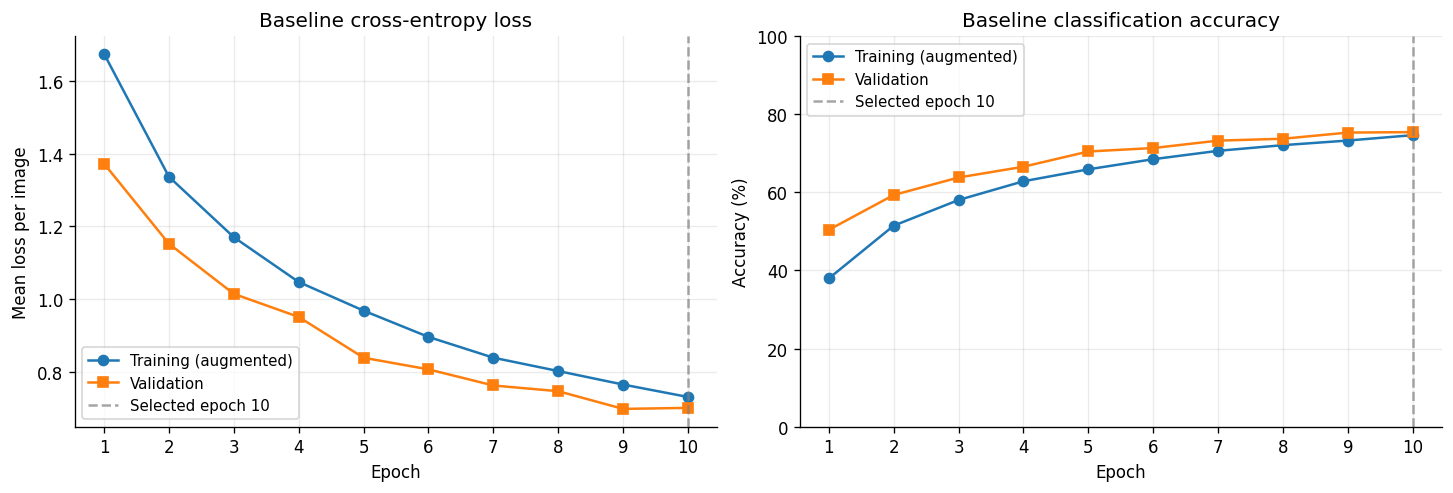

| Model | Parameters | Selected epoch | Training accuracy at that epoch* | Validation accuracy | Total fitting time |
|:--|--:|--:|--:|--:|--:|
| Baseline CNN | 356,810 | 10 | 74.62% | 75.40% | 171.1 s |

*Training accuracy is the online, augmented training metric, not a separate evaluation of the saved checkpoint.

Across 10 epochs, training loss changed from **1.6745** to **0.7317**, while validation loss changed from **1.3727** to **0.7018**. Validation accuracy changed from **50.38%** to **75.40%**. The selected checkpoint is epoch **10**, with validation accuracy **75.40%**. These are results from one seeded run; run-to-run variation has not been measured. The best checkpoint is restored in `baseline`. Dropout and downsampling comparisons belong to Part 3, and the held-out test evaluation belongs to Part 4.

In [10]:
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(epochs, [row["train_loss"] for row in history], "o-", label="Training (augmented)")
axes[0].plot(epochs, [row["val_loss"] for row in history], "s-", label="Validation")
axes[0].set(title="Baseline cross-entropy loss", xlabel="Epoch", ylabel="Mean loss per image")
axes[1].plot(epochs, [100 * row["train_accuracy"] for row in history], "o-", label="Training (augmented)")
axes[1].plot(epochs, [100 * row["val_accuracy"] for row in history], "s-", label="Validation")
axes[1].set(title="Baseline classification accuracy", xlabel="Epoch", ylabel="Accuracy (%)", ylim=(0, 100))
for ax in axes:
    ax.axvline(best_checkpoint["epoch"], color="grey", linestyle="--", alpha=0.7,
               label=f"Selected epoch {best_checkpoint['epoch']}")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
plt.show()

selected = history[best_checkpoint["epoch"] - 1]
display(Markdown(
    f"| Model | Parameters | Selected epoch | Training accuracy at that epoch* | Validation accuracy | Total fitting time |\n"
    f"|:--|--:|--:|--:|--:|--:|\n"
    f"| Baseline CNN | {count_parameters(baseline):,} | {selected['epoch']} | "
    f"{selected['train_accuracy']:.2%} | {selected['val_accuracy']:.2%} | {total_training_seconds:.1f} s |\n\n"
    "*Training accuracy is the online, augmented training metric, not a separate evaluation of the saved checkpoint."
))

first, last = history[0], history[-1]
display(Markdown(
    f"Across {len(history)} epochs, training loss changed from **{first['train_loss']:.4f}** "
    f"to **{last['train_loss']:.4f}**, while validation loss changed from "
    f"**{first['val_loss']:.4f}** to **{last['val_loss']:.4f}**. "
    f"Validation accuracy changed from **{first['val_accuracy']:.2%}** to "
    f"**{last['val_accuracy']:.2%}**. The selected checkpoint is epoch **{selected['epoch']}**, "
    f"with validation accuracy **{selected['val_accuracy']:.2%}**. "
    "These are results from one seeded run; run-to-run variation has not been measured. "
    "The best checkpoint is restored in `baseline`. Dropout and downsampling comparisons "
    "belong to Part 3, and the held-out test evaluation belongs to Part 4."
))

In [11]:
# Verify the saved checkpoint and all ten recorded epochs without using the test loader.
saved = torch.load(ARTIFACT_DIR / "baseline_best.pt", map_location=DEVICE, weights_only=True)
assert len(history) == EPOCHS
assert all(np.isfinite(row[key]) for row in history
           for key in ("train_loss", "val_loss", "train_accuracy", "val_accuracy"))
assert all(0 <= row[key] <= 1 for row in history
           for key in ("train_accuracy", "val_accuracy"))
assert saved["epoch"] == max(history, key=lambda row: row["val_accuracy"])["epoch"]
assert all(torch.equal(value, saved["model_state_dict"][name])
           for name, value in baseline.state_dict().items())
restored_loss, restored_accuracy = run_epoch(baseline, val_loader, nn.CrossEntropyLoss())
assert abs(restored_accuracy - saved["val_accuracy"]) < 1e-12
print("Checks passed: split is disjoint, model has 10 logits and no dropout, all epochs are recorded,")
print("and the restored checkpoint reproduces its selected validation accuracy.")
print("The test loader has not been used for training, selection, or evaluation.")

Checks passed: split is disjoint, model has 10 logits and no dropout, all epochs are recorded,
and the restored checkpoint reproduces its selected validation accuracy.
The test loader has not been used for training, selection, or evaluation.


# Part 3 - Compare dropout and downsampling

We investigate how dropout and learned downsampling affect the baseline CNN.
We compare three models: the baseline, a dropout variant, and a stride-2
convolution variant.

For a fair comparison, all models are trained from scratch using the same
training and validation split, preprocessing, seed **42**, cross-entropy loss,
**Adam**, learning rate **0.001**, batch size **128**, and **10 epochs**.
The original test set remains reserved for Part 4.

### A. Add dropout to the baseline

We insert `nn.Dropout(p=0.5)` after the classifier's 128-unit ReLU and before
the final linear layer. All other layers remain unchanged. Dropout has no
trainable parameters, so this model retains the baseline's **356,810 parameters**.

During training, dropout randomly sets half of the hidden activations to zero
on average and scales the retained activations to preserve their expected value.
This discourages reliance on particular combinations of activations and may
reduce overfitting. During validation, `model.eval()` disables dropout.

We compare the learning curves to determine whether dropout improves validation
performance or reduces signs of overfitting. It may also slow learning or cause
underfitting within the fixed epoch budget.

### B. Replace max pooling with stride-2 convolutions

Starting from the baseline without dropout, we replace each **2 × 2 max-pooling
layer with stride 2** with a **3 × 3 convolution with stride 2 and padding 1**.
Each replacement preserves its input channel count: **32, 64, and 128**.
The original convolutions, ReLUs, and classification head remain unchanged;
no additional ReLU is introduced.

Max pooling selects the largest activation within each local region.
Stride-2 convolutions instead learn weighted combinations while reducing
spatial resolution.

The feature-map shapes remain unchanged:

| Stage | Baseline | Stride-2 convolution variant |
|:--|:--|:--|
| Input | 3 × 32 × 32 | 3 × 32 × 32 |
| First downsampling | 32 × 16 × 16 | 32 × 16 × 16 |
| Second downsampling | 64 × 8 × 8 | 64 × 8 × 8 |
| Third downsampling | 128 × 4 × 4 | 128 × 4 × 4 |
| Classifier output | 10 logits | 10 logits |

Unlike pooling, the replacement convolutions contain trainable weights and
biases. They add **193,760 parameters**, increasing the total from **356,810**
to **550,570**.

### Receptive-field comparison

The receptive field describes the input region that can influence an individual
feature-map activation. Starting with receptive-field size `r = 1` and sampling
jump `j = 1`, each convolution or pooling operation updates them as follows:

`r_new = r + (kernel_size - 1) × j`

`j_new = j × stride`

| Stage | Baseline receptive field | Stride-convolution receptive field | Sampling jump |
|:--|--:|--:|--:|
| First downsampling | 4 × 4 | 5 × 5 | 2 |
| Second downsampling | 10 × 10 | 13 × 13 | 4 |
| Third downsampling | 22 × 22 | 29 × 29 | 8 |

These are theoretical receptive fields for individual spatial activations,
including padding. The fully connected classifier combines all final spatial
positions. Because the stride-convolution variant also increases parameter
count and receptive-field size, any performance difference cannot be attributed
solely to learning the downsampling operation.

In [12]:
class DropoutCNN(BaselineCNN):
    def __init__(self, p=0.5):
        super().__init__()
        self.classifier = nn.Sequential(OrderedDict([
            ("flatten", self.classifier.flatten),
            ("fc1", self.classifier.fc1),
            ("relu4", self.classifier.relu4),
            ("dropout", nn.Dropout(p=p)),
            ("logits", self.classifier.logits),
        ]))


class StridedCNN(BaselineCNN):
    def __init__(self):
        super().__init__()
        # These convolutions preserve channels and halve spatial dimensions
        for name, channels in [
            ("pool1", 32),
            ("pool2", 64),
            ("pool3", 128),
        ]:
            self.features._modules[name] = nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                stride=2,
                padding=1,
            )


# These come from the baseline trained
assert len(history) == EPOCHS
assert count_parameters(baseline) == 356_810

histories = {"baseline": [dict(row) for row in history]}
checkpoints = {"baseline": best_checkpoint}
training_times = {"baseline": total_training_seconds}
models = {"baseline": baseline}

model_factories = {
    "baseline": BaselineCNN,
    "dropout": DropoutCNN,
    "strided": StridedCNN,
}

print("Model definitions ready.")
print("Baseline results retained from Part 2.")

Model definitions ready.
Baseline results retained from Part 2.


In [13]:
def feature_details(model):
    model.eval()
    x = torch.zeros(1, 3, 32, 32)

    receptive_field = 1
    jump = 1
    rows = []

    def first(value):
        return value[0] if isinstance(value, tuple) else value

    with torch.no_grad():
        for name, layer in model.features.named_children():
            x = layer(x)

            if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):
                kernel = first(layer.kernel_size)
                stride = first(layer.stride)
                dilation = first(layer.dilation)

                receptive_field += (
                    (kernel - 1) * dilation * jump
                )
                jump *= stride

                rows.append({
                    "layer": name,
                    "operation": type(layer).__name__,
                    "shape": tuple(x.shape),
                    "rf": receptive_field,
                    "jump": jump,
                })

    assert model(torch.zeros(2, 3, 32, 32)).shape == (2, 10)
    return rows


architecture_stats = {}

for name, factory in model_factories.items():
    model = factory()
    details = feature_details(model)

    architecture_stats[name] = {
        "parameters": count_parameters(model),
        "final_feature_shape": list(details[-1]["shape"]),
        "final_feature_receptive_field": details[-1]["rf"],
    }

    table = [
        f"### {name.capitalize()}",
        "",
        "| Layer | Operation | Output shape | Receptive field | Jump |",
        "|:--|:--|:--|--:|--:|",
    ]

    for row in details:
        table.append(
            f"| {row['layer']} | {row['operation']} | "
            f"{row['shape']} | {row['rf']} | {row['jump']} |"
        )

    table += [
        "",
        f"Trainable parameters: **{count_parameters(model):,}**",
    ]
    display(Markdown("\n".join(table)))

assert architecture_stats["dropout"]["parameters"] == 356_810
assert architecture_stats["strided"]["parameters"] == 550_570
assert architecture_stats["baseline"]["final_feature_receptive_field"] == 22
assert architecture_stats["strided"]["final_feature_receptive_field"] == 29

### Baseline

| Layer | Operation | Output shape | Receptive field | Jump |
|:--|:--|:--|--:|--:|
| conv1 | Conv2d | (1, 32, 32, 32) | 3 | 1 |
| pool1 | MaxPool2d | (1, 32, 16, 16) | 4 | 2 |
| conv2 | Conv2d | (1, 64, 16, 16) | 8 | 2 |
| pool2 | MaxPool2d | (1, 64, 8, 8) | 10 | 4 |
| conv3 | Conv2d | (1, 128, 8, 8) | 18 | 4 |
| pool3 | MaxPool2d | (1, 128, 4, 4) | 22 | 8 |

Trainable parameters: **356,810**

### Dropout

| Layer | Operation | Output shape | Receptive field | Jump |
|:--|:--|:--|--:|--:|
| conv1 | Conv2d | (1, 32, 32, 32) | 3 | 1 |
| pool1 | MaxPool2d | (1, 32, 16, 16) | 4 | 2 |
| conv2 | Conv2d | (1, 64, 16, 16) | 8 | 2 |
| pool2 | MaxPool2d | (1, 64, 8, 8) | 10 | 4 |
| conv3 | Conv2d | (1, 128, 8, 8) | 18 | 4 |
| pool3 | MaxPool2d | (1, 128, 4, 4) | 22 | 8 |

Trainable parameters: **356,810**

### Strided

| Layer | Operation | Output shape | Receptive field | Jump |
|:--|:--|:--|--:|--:|
| conv1 | Conv2d | (1, 32, 32, 32) | 3 | 1 |
| pool1 | Conv2d | (1, 32, 16, 16) | 5 | 2 |
| conv2 | Conv2d | (1, 64, 16, 16) | 9 | 2 |
| pool2 | Conv2d | (1, 64, 8, 8) | 13 | 4 |
| conv3 | Conv2d | (1, 128, 8, 8) | 21 | 4 |
| pool3 | Conv2d | (1, 128, 4, 4) | 29 | 8 |

Trainable parameters: **550,570**

### Architecture comparison

Dropout adds no trainable parameters, so the baseline and dropout models
both contain **356,810 parameters**. Dropout is active during training and
disabled during validation through `model.train()` and `model.eval()`.

The strided model contains **550,570 parameters**, an increase of
**193,760**, because learned convolutions replace parameter-free pooling.

All models retain the same downsampled feature-map shapes:
**32 × 16 × 16**, **64 × 8 × 8**, and **128 × 4 × 4**.

For receptive-field calculations, we start with receptive field r = 1
and jump j = 1. Each spatial layer updates these as:

- r_new = r_old + (kernel_size − 1) × dilation × j_old
- j_new = j_old × stride

The final feature-map receptive field increases from **22 × 22**
in the baseline to **29 × 29** in the strided model. These are theoretical
receptive fields before accounting for image boundaries and padding.
The classifier combines all final spatial positions.

No extra ReLU is added after the replacement convolutions, keeping the
remaining architecture unchanged. This experiment changes both the
downsampling operation and model capacity, which limits causal conclusions.

In [14]:
for name in ("dropout", "strided"):
    print(f"\n{'=' * 20} {name.upper()} {'=' * 20}")

    # Match the baseline's fresh initialization and loader setup
    seed_everything(SEED)
    current_train_loader, current_val_loader, _ = make_loaders(SEED)
    model = model_factories[name]().to(DEVICE)

    model_history, checkpoint, seconds = fit_model(
        model,
        current_train_loader,
        current_val_loader,
        epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
        checkpoint_path=ARTIFACT_DIR / f"{name}_best.pt",
    )

    models[name] = model
    histories[name] = model_history
    checkpoints[name] = checkpoint
    training_times[name] = seconds

    print(
        f"Selected epoch: {checkpoint['epoch']} | "
        f"Validation accuracy: {checkpoint['val_accuracy']:.2%} | "
        f"Total fitting time: {seconds:.1f} s"
    )


# Save all three histories and metadata for next part
experiment_results = {}

for name in model_factories:
    model_history = histories[name]
    checkpoint = checkpoints[name]
    selected = next(
        row for row in model_history
        if row["epoch"] == checkpoint["epoch"]
    )

    with (ARTIFACT_DIR / f"{name}_history.csv").open(
        "w", newline=""
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(model_history[0])
        )
        writer.writeheader()
        writer.writerows(model_history)

    experiment_results[name] = {
        "model_class": model_factories[name].__name__,
        **architecture_stats[name],
        "selected_epoch": checkpoint["epoch"],
        "selected_train_accuracy": selected["train_accuracy"],
        "selected_val_accuracy": selected["val_accuracy"],
        "total_training_seconds": training_times[name],
        "epoch_training_validation_seconds": sum(
            row["epoch_seconds"] for row in model_history
        ),
        "hardware": hardware,
        "device": str(DEVICE),
        "cpu_threads": torch.get_num_threads(),
        "torch_version": str(torch.__version__),
        "torchvision_version": str(torchvision.__version__),
        "dropout_probability": 0.5 if name == "dropout" else 0.0,
        **checkpoint["config"],
    }

with (ARTIFACT_DIR / "part3_results.json").open("w") as file:
    json.dump(experiment_results, file, indent=2)

print("\nAll three models have histories, metadata, and best checkpoints.")
print("The test set has not been evaluated.")


==================== DROPOUT ====================
Epoch | Train loss | Val loss | Train accuracy | Val accuracy | Seconds
    1 |     1.8257 |   1.5333 |        32.04% |      44.64% |    17.2
    2 |     1.5185 |   1.2747 |        44.26% |      53.04% |    17.0
    3 |     1.3912 |   1.1813 |        49.31% |      57.46% |    17.0
    4 |     1.2763 |   1.0653 |        53.90% |      61.02% |    17.0
    5 |     1.1922 |   0.9678 |        57.44% |      64.56% |    17.0
    6 |     1.1220 |   0.8886 |        60.52% |      67.96% |    16.9
    7 |     1.0616 |   0.8953 |        62.70% |      67.90% |    17.0
    8 |     1.0101 |   0.8113 |        64.72% |      71.32% |    17.2
    9 |     0.9805 |   0.7810 |        65.95% |      72.22% |    17.0
   10 |     0.9342 |   0.7896 |        67.40% |      71.90% |    17.3
Selected epoch: 9 | Validation accuracy: 72.22% | Total fitting time: 170.5 s

==================== STRIDED ====================
Epoch | Train loss | Val loss | Train accuracy |

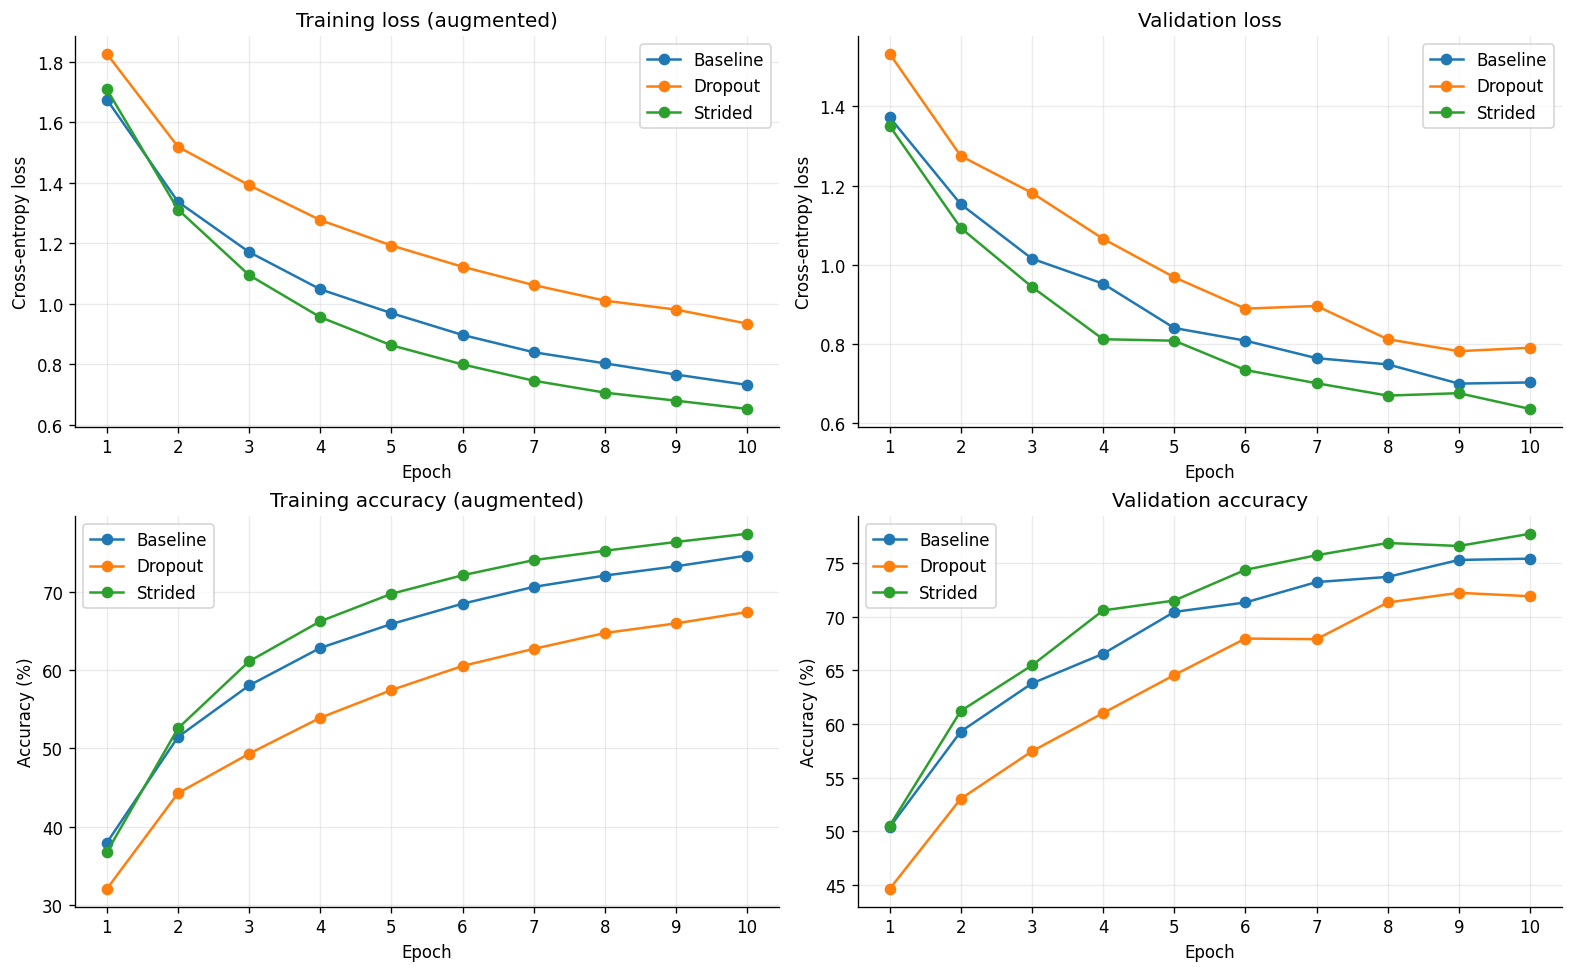

| Model | Parameters | Selected epoch | Train accuracy* | Validation accuracy | Total fitting time |
|:--|--:|--:|--:|--:|--:|
| Baseline | 356,810 | 10 | 74.62% | 75.40% | 171.1 s |
| Dropout | 356,810 | 9 | 65.95% | 72.22% | 170.5 s |
| Strided | 550,570 | 10 | 77.40% | 77.72% | 174.2 s |

*Training accuracy is recorded during training on augmented images, with dropout active for the dropout model. It is not a separate evaluation of the selected checkpoint.

**Hardware:** NVIDIA L4. **Timing:** We reuse Part 2's synchronized `time.perf_counter()` measurement. Total fitting time includes training, validation, logging, and checkpoint writes; it excludes data download, model setup, final checkpoint restoration, and plotting.

Dropout versus baseline: -3.18 percentage points validation accuracy; 1.00x total fitting time.
Strided versus baseline: +2.32 percentage points validation accuracy; 1.02x total fitting time.


In [15]:
colors = {
    "baseline": "tab:blue",
    "dropout": "tab:orange",
    "strided": "tab:green",
}

fig, axes = plt.subplots(
    2, 2, figsize=(13, 8), constrained_layout=True
)

panels = [
    ("train_loss", "Training loss (augmented)", "Cross-entropy loss"),
    ("val_loss", "Validation loss", "Cross-entropy loss"),
    ("train_accuracy", "Training accuracy (augmented)", "Accuracy (%)"),
    ("val_accuracy", "Validation accuracy", "Accuracy (%)"),
]

for ax, (metric, title, ylabel) in zip(axes.flat, panels):
    for name, model_history in histories.items():
        scale = 100 if "accuracy" in metric else 1
        ax.plot(
            [row["epoch"] for row in model_history],
            [scale * row[metric] for row in model_history],
            "o-",
            color=colors[name],
            label=name.capitalize(),
        )

    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.grid(alpha=0.25)
    ax.legend()

fig.savefig(
    ARTIFACT_DIR / "part3_learning_curves.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

table = [
    "| Model | Parameters | Selected epoch | Train accuracy* | "
    "Validation accuracy | Total fitting time |",
    "|:--|--:|--:|--:|--:|--:|",
]

for name, result in experiment_results.items():
    table.append(
        f"| {name.capitalize()} | {result['parameters']:,} | "
        f"{result['selected_epoch']} | "
        f"{result['selected_train_accuracy']:.2%} | "
        f"{result['selected_val_accuracy']:.2%} | "
        f"{result['total_training_seconds']:.1f} s |"
    )

display(Markdown("\n".join(table)))

display(Markdown(
    "*Training accuracy is recorded during training on augmented images, "
    "with dropout active for the dropout model. It is not a separate "
    "evaluation of the selected checkpoint.\n\n"
    f"**Hardware:** {hardware}. "
    "**Timing:** We reuse Part 2's synchronized `time.perf_counter()` "
    "measurement. Total fitting time includes training, validation, "
    "logging, and checkpoint writes; it excludes data download, model "
    "setup, final checkpoint restoration, and plotting."
))

base = experiment_results["baseline"]

for name in ("dropout", "strided"):
    result = experiment_results[name]
    accuracy_change = 100 * (
        result["selected_val_accuracy"] - base["selected_val_accuracy"]
    )
    time_ratio = (
        result["total_training_seconds"] /
        base["total_training_seconds"]
    )
    print(
        f"{name.capitalize()} versus baseline: "
        f"{accuracy_change:+.2f} percentage points validation accuracy; "
        f"{time_ratio:.2f}x total fitting time."
    )

### Discussion

**Dropout.** Adding dropout with probability 0.5 produced a selected
validation accuracy of 72.22% (epoch 9), compared with 75.40% for the
baseline (epoch 10), a decrease of 3.18 percentage points.

Both models' training losses decreased throughout the 10 epochs, and
their validation losses fell overall, with only small single-epoch
increases (for example, the baseline's rose from 0.6989 to 0.7018 in
the final epoch). The baseline did not show a sustained increase in validation
loss while training loss decreased, so there is no clear evidence that
dropout reduced overfitting in this experiment. Instead, dropout appears
to have slowed learning within the fixed epoch budget. Its final
validation loss was 0.7896, compared with 0.7018 for the baseline.

Training accuracy alone cannot establish overfitting because training
uses augmented images and changing weights, with dropout enabled for
the dropout model. Validation uses fixed preprocessing and disables
dropout.

**Downsampling.** Replacing max pooling with stride-2 convolutions
increased selected validation accuracy from 75.40% to 77.72%, an
improvement of 2.32 percentage points. Total fitting time increased
from 171.1 to 174.2 seconds, approximately 1.8%.

Feature-map dimensions remained unchanged. Parameter count increased
from 356,810 to 550,570, and the final feature-map receptive field
increased from 22 × 22 to 29 × 29.

The learned downsampling model achieved better validation performance
in this run, at the cost of additional parameters and training time.
Because model capacity and receptive-field size also changed, this
improvement cannot be attributed solely to the downsampling operation.

**Limitations.** Each model was trained once with seed 42 for 10 epochs.
The baseline and strided models achieved their highest validation
accuracy at the final epoch and the dropout model at epoch 9, so
longer training could change their relative performance.
We tested only one dropout probability and one strided-convolution
design. Run-to-run variation was not measured. The test set remains
reserved for Part 4.

# Part 4 - Model selection and evaluation

**One selection rule for every model.** Each model's checkpoint is the epoch with the
**highest validation accuracy, keeping the earliest epoch on a tie**. This is the rule that
`fit_model` applied during training. Below we re-derive that epoch from each model's history,
reload the saved checkpoint from disk, and confirm that it reproduces the recorded validation
accuracy, so the table describes the weights that were saved.

**Two training accuracies.** The online*\ training accuracy is the metric logged during the
selected epoch (augmented images, dropout active, weights changing within the epoch). The
*checkpoint* training accuracy re-evaluates the saved weights on the same 45,000 training
images in `eval()` mode without augmentation. Only the checkpoint figure is directly comparable
with validation accuracy.

**Hardware and timing method.** All three models were trained in the same session on the same
device (printed under the table). Training time is wall-clock time from `time.perf_counter()`,
with `torch.cuda.synchronize()` called before each reading so that queued GPU work is counted.
*Total fitting time* covers all 10 epochs of training and validation, including logging and
checkpoint writes. It excludes data download, model construction, checkpoint restoration and
plotting. *Mean epoch time* is the average per-epoch training and validation time.

The test set is used **once**, and only for the single model chosen from validation results.

In [ ]:
# Re-apply the selection rule, reload every saved checkpoint, and compare the models.
def select_checkpoint_epoch(model_history):
    # Highest validation accuracy; earliest epoch on a tie (the rule used by fit_model).
    best_accuracy = max(row["val_accuracy"] for row in model_history)
    return next(row for row in model_history if row["val_accuracy"] == best_accuracy)

def load_checkpoint(name):
    saved = torch.load(ARTIFACT_DIR / f"{name}_best.pt", map_location="cpu", weights_only=True)
    model = model_factories[name]()
    model.load_state_dict(saved["model_state_dict"])
    return model.to(DEVICE).eval(), saved

# The 45,000 training images with the deterministic evaluation transform (no augmentation).
train_eval_loader = DataLoader(
    Subset(full_train_evaluation, train_indices), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
evaluation_loss = nn.CrossEntropyLoss()

display_names = {"baseline": "Baseline (max pool)",
                 "dropout": "Dropout (p = 0.5)",
                 "strided": "Stride-2 convolutions"}

comparison = {}
for name in model_factories:
    selected_row = select_checkpoint_epoch(histories[name])
    model, saved = load_checkpoint(name)
    assert saved["epoch"] == selected_row["epoch"] == checkpoints[name]["epoch"], name
    assert saved["config"]["selection_rule"] == "highest validation accuracy; earliest tie"

    # Validation only: the reloaded checkpoint must reproduce its recorded accuracy.
    val_loss, val_accuracy = run_epoch(model, val_loader, evaluation_loss)
    assert abs(val_accuracy - saved["val_accuracy"]) < 1e-12, name
    clean_train_loss, clean_train_accuracy = run_epoch(model, train_eval_loader, evaluation_loss)

    epoch_seconds = [row["epoch_seconds"] for row in histories[name]]
    models[name] = model
    comparison[name] = {
        "parameters": count_parameters(model),
        "selected_epoch": saved["epoch"],
        "online_train_accuracy": selected_row["train_accuracy"],
        "checkpoint_train_accuracy": clean_train_accuracy,
        "checkpoint_train_loss": clean_train_loss,
        "val_accuracy": val_accuracy,
        "val_loss": val_loss,
        "total_training_seconds": training_times[name],
        "mean_epoch_seconds": float(np.mean(epoch_seconds)),
    }

table = ["| Model | Parameters | Selected epoch | Train acc. (online, augmented) | "
         "Train acc. (checkpoint, clean) | Validation acc. | Validation loss | "
         "Total fitting time | Mean epoch time |",
         "|:--|--:|--:|--:|--:|--:|--:|--:|--:|"]
for name, r in comparison.items():
    table.append(
        f"| {display_names[name]} | {r['parameters']:,} | {r['selected_epoch']} of {EPOCHS} | "
        f"{r['online_train_accuracy']:.2%} | {r['checkpoint_train_accuracy']:.2%} | "
        f"{r['val_accuracy']:.2%} | {r['val_loss']:.4f} | "
        f"{r['total_training_seconds']:.1f} s | {r['mean_epoch_seconds']:.1f} s |")
display(Markdown("\n".join(table)))

display(Markdown(
    f"**Hardware:** {hardware} (`{DEVICE}`), {torch.get_num_threads()} CPU threads, "
    f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
    f"torchvision {torchvision.__version__}. "
    "**Timing:** synchronized `time.perf_counter()` wall-clock time, as described above. "
    "Data loading runs on the CPU in the main process (`num_workers=0`), so these times describe "
    "this environment rather than the models' compute cost alone. They come from a single run "
    "on a shared cloud GPU and can vary by several percent between runs."))

| Model | Parameters | Selected epoch | Train acc. (online, augmented) | Train acc. (checkpoint, clean) | Validation acc. | Validation loss | Total fitting time | Mean epoch time |
|:--|--:|--:|--:|--:|--:|--:|--:|--:|
| Baseline (max pool) | 356,810 | 10 of 10 | 74.62% | 77.98% | 75.40% | 0.7018 | 171.1 s | 17.1 s |
| Dropout (p = 0.5) | 356,810 | 9 of 10 | 65.95% | 73.37% | 72.22% | 0.7810 | 170.5 s | 17.0 s |
| Stride-2 convolutions | 550,570 | 10 of 10 | 77.40% | 80.94% | 77.72% | 0.6349 | 174.2 s | 17.4 s |

**Hardware:** NVIDIA L4 (`cuda`), 4 CPU threads, Python 3.13.16, PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130. **Timing:** synchronized `time.perf_counter()` wall-clock time, as described above. Data loading runs on the CPU in the main process (`num_workers=0`), so these times describe this environment rather than the models' compute cost alone. They come from a single run on a shared cloud GPU and can vary by several percent between runs.

### Choosing one model from validation results only

We choose the model whose selected checkpoint has the **highest validation accuracy**. Had two
models tied, we would have preferred fewer parameters, then shorter training time. No test result
is consulted. Because 5,000 validation images give only a finite sample, we report an approximate
95% interval for each validation accuracy, using the normal approximation
`p ± 1.96·sqrt(p(1 − p)/n)`. We also make a paired comparison of the top two models on the
same validation images: how many images only one of the two models classifies correctly.

In [17]:
# Select one model using validation results only.
@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for images, labels in loader:
        all_logits.append(model(images.to(DEVICE)).float().cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)

def accuracy_interval(accuracy, n):
    half_width = 1.96 * np.sqrt(accuracy * (1 - accuracy) / n)
    return accuracy - half_width, accuracy + half_width

ranking = sorted(comparison, key=lambda n: (-comparison[n]["val_accuracy"],
                                            comparison[n]["parameters"],
                                            comparison[n]["total_training_seconds"]))
chosen_name, runner_up = ranking[0], ranking[1]
chosen_model = models[chosen_name]
n_val = len(val_dataset)

for rank, name in enumerate(ranking, 1):
    accuracy = comparison[name]["val_accuracy"]
    low, high = accuracy_interval(accuracy, n_val)
    print(f"{rank}. {display_names[name]:<22} validation accuracy {accuracy:.2%} "
          f"(95% CI {low:.2%} to {high:.2%}; {round(accuracy * n_val):,}/{n_val:,} correct)")

# Paired comparison on identical validation images.
chosen_val_logits, val_labels_tensor = predict(chosen_model, val_loader)
runner_val_logits, _ = predict(models[runner_up], val_loader)
chosen_right = chosen_val_logits.argmax(dim=1) == val_labels_tensor
runner_right = runner_val_logits.argmax(dim=1) == val_labels_tensor
assert chosen_right.sum().item() == round(comparison[chosen_name]["val_accuracy"] * n_val)
only_chosen = (chosen_right & ~runner_right).sum().item()
only_runner = (~chosen_right & runner_right).sum().item()

gap = comparison[chosen_name]["val_accuracy"] - comparison[runner_up]["val_accuracy"]
print(f"\nSelected model: {display_names[chosen_name]} (checkpoint epoch "
      f"{comparison[chosen_name]['selected_epoch']})")
print(f"Margin over {display_names[runner_up]}: {100 * gap:+.2f} percentage points. "
      f"On the same validation images, only the selected model is right on {only_chosen} "
      f"images and only the runner-up is right on {only_runner}.")

1. Stride-2 convolutions  validation accuracy 77.72% (95% CI 76.57% to 78.87%; 3,886/5,000 correct)
2. Baseline (max pool)    validation accuracy 75.40% (95% CI 74.21% to 76.59%; 3,770/5,000 correct)
3. Dropout (p = 0.5)      validation accuracy 72.22% (95% CI 70.98% to 73.46%; 3,611/5,000 correct)

Selected model: Stride-2 convolutions (checkpoint epoch 10)
Margin over Baseline (max pool): +2.32 percentage points. On the same validation images, only the selected model is right on 487 images and only the runner-up is right on 371.


### Test-set evaluation of the selected checkpoint

The chosen checkpoint is evaluated on the 10,000 original test images, which have not been used
for training, checkpoint selection or model selection. We evaluate it in a single pass and keep
the logits for the confusion matrix and the examples. Per-class accuracy is the fraction of each
true class that the model labels correctly (the confusion-matrix row diagonal divided by the row
total). We also report precision, the fraction of predictions of a class that are correct.

In [ ]:
# Evaluate only the chosen checkpoint on the untouched test set.
synchronize_device()
test_start = time.perf_counter()
test_logits, test_labels = predict(chosen_model, test_loader)
synchronize_device()
test_seconds = time.perf_counter() - test_start

assert len(test_labels) == len(test_dataset) == 10_000
assert torch.equal(test_labels, torch.as_tensor(test_dataset.targets))

test_probabilities = test_logits.softmax(dim=1)
test_confidence, test_predictions = (t.numpy() for t in test_probabilities.max(dim=1))
test_labels_np = test_labels.numpy()
test_correct = test_predictions == test_labels_np
test_accuracy = float(test_correct.mean())
test_loss = nn.functional.cross_entropy(test_logits, test_labels).item()
test_low, test_high = accuracy_interval(test_accuracy, len(test_dataset))
chosen_val_accuracy = comparison[chosen_name]["val_accuracy"]

print(f"Model: {display_names[chosen_name]} | checkpoint epoch {comparison[chosen_name]['selected_epoch']}")
print(f"Test accuracy: {test_accuracy:.2%} ({test_correct.sum():,}/{len(test_dataset):,} correct; "
      f"95% CI {test_low:.2%} to {test_high:.2%})")
print(f"Test loss: {test_loss:.4f}")
print(f"Validation accuracy of the same checkpoint: {chosen_val_accuracy:.2%} "
      f"(test minus validation: {100 * (test_accuracy - chosen_val_accuracy):+.2f} percentage points)")
print(f"Test inference time: {test_seconds:.1f} s for 10,000 images on {hardware}")

Model: Stride-2 convolutions | checkpoint epoch 10
Test accuracy: 78.53% (7,853/10,000 correct; 95% CI 77.73% to 79.33%)
Test loss: 0.6497
Validation accuracy of the same checkpoint: 77.72% (test minus validation: +0.81 percentage points)
Test inference time: 2.1 s for 10,000 images on NVIDIA L4


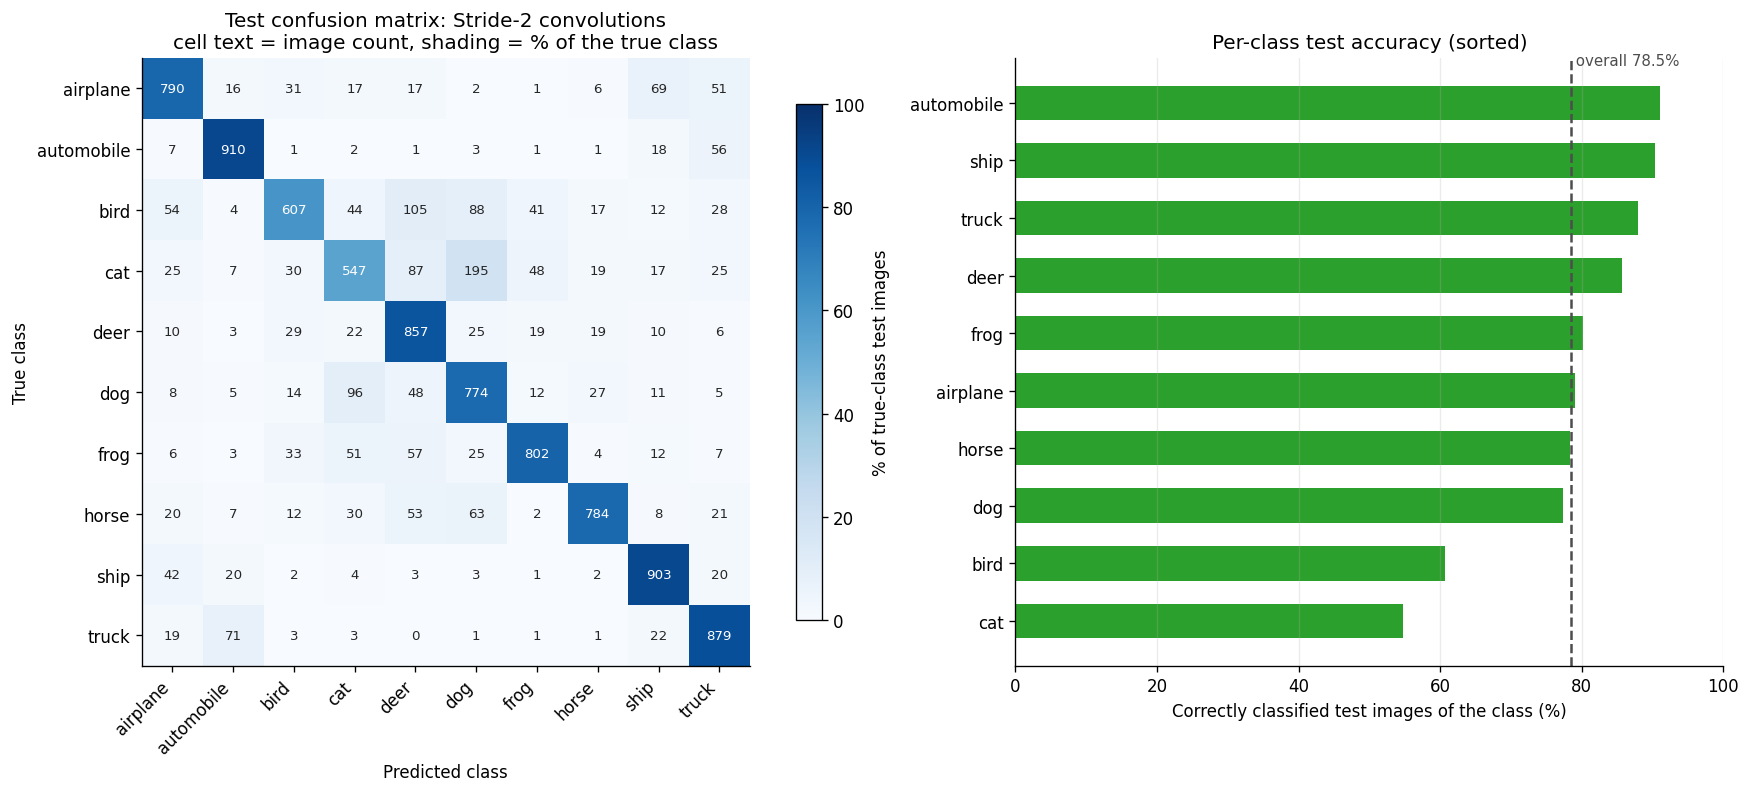

| Class | Test images | Correct | Per-class accuracy | Precision | Most frequent wrong prediction |
|:--|--:|--:|--:|--:|:--|
| airplane | 1,000 | 790 | 79.0% | 80.5% | ship (69) |
| automobile | 1,000 | 910 | 91.0% | 87.0% | truck (56) |
| bird | 1,000 | 607 | 60.7% | 79.7% | deer (105) |
| cat | 1,000 | 547 | 54.7% | 67.0% | dog (195) |
| deer | 1,000 | 857 | 85.7% | 69.8% | bird (29) |
| dog | 1,000 | 774 | 77.4% | 65.6% | cat (96) |
| frog | 1,000 | 802 | 80.2% | 86.4% | deer (57) |
| horse | 1,000 | 784 | 78.4% | 89.1% | dog (63) |
| ship | 1,000 | 903 | 90.3% | 83.5% | airplane (42) |
| truck | 1,000 | 879 | 87.9% | 80.1% | automobile (71) |
| **All** | **10,000** | **7,853** | **78.53%** | | |

Most frequent individual confusions (true -> predicted):
         cat -> dog         195 images (19.5% of cat)
        bird -> deer        105 images (10.5% of bird)
         dog -> cat          96 images (9.6% of dog)
        bird -> dog          88 images (8.8% of bird)
         cat -> deer         87 images (8.7% of cat)


In [19]:
# Labeled confusion matrix and per-class accuracy.
num_classes = len(class_names)
confusion = np.zeros((num_classes, num_classes), dtype=int)
np.add.at(confusion, (test_labels_np, test_predictions), 1)    # rows = true, columns = predicted
assert confusion.sum() == len(test_dataset) and np.trace(confusion) == test_correct.sum()

class_totals = confusion.sum(axis=1)
per_class_accuracy = confusion.diagonal() / class_totals
per_class_precision = confusion.diagonal() / np.maximum(confusion.sum(axis=0), 1)
row_share = confusion / class_totals[:, None]
off_diagonal = confusion.copy()
np.fill_diagonal(off_diagonal, 0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
heatmap = ax.imshow(100 * row_share, cmap="Blues", vmin=0, vmax=100)
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, f"{confusion[i, j]}", ha="center", va="center", fontsize=8,
                color="white" if row_share[i, j] > 0.5 else "0.15")
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class",
       title=f"Test confusion matrix: {display_names[chosen_name]}\n"
             "cell text = image count, shading = % of the true class")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.colorbar(heatmap, ax=ax, shrink=0.85, label="% of true-class test images")

ax = axes[1]
order = np.argsort(per_class_accuracy)
ax.barh(np.arange(num_classes), 100 * per_class_accuracy[order], height=0.6,
        color=colors[chosen_name])
ax.axvline(100 * test_accuracy, color="0.3", linestyle="--", linewidth=1.5)
ax.text(100 * test_accuracy, num_classes - 0.4, f" overall {test_accuracy:.1%}",
        color="0.3", va="bottom", fontsize=9)
ax.set(yticks=np.arange(num_classes), yticklabels=[class_names[i] for i in order],
       xlim=(0, 100), xlabel="Correctly classified test images of the class (%)",
       title="Per-class test accuracy (sorted)")
ax.grid(axis="x", alpha=0.25)
fig.savefig(ARTIFACT_DIR / "part4_confusion_per_class.png", dpi=180, bbox_inches="tight")
plt.show()

rows = ["| Class | Test images | Correct | Per-class accuracy | Precision | Most frequent wrong prediction |",
        "|:--|--:|--:|--:|--:|:--|"]
for i, class_name in enumerate(class_names):
    j = int(off_diagonal[i].argmax())
    rows.append(f"| {class_name} | {class_totals[i]:,} | {confusion[i, i]:,} | "
                f"{per_class_accuracy[i]:.1%} | {per_class_precision[i]:.1%} | "
                f"{class_names[j]} ({off_diagonal[i, j]}) |")
rows.append(f"| **All** | **{class_totals.sum():,}** | **{np.trace(confusion):,}** | "
            f"**{test_accuracy:.2%}** | | |")
display(Markdown("\n".join(rows)))

print("Most frequent individual confusions (true -> predicted):")
for flat_index in np.argsort(off_diagonal, axis=None)[::-1][:5]:
    i, j = np.unravel_index(flat_index, off_diagonal.shape)
    print(f"  {class_names[i]:>10} -> {class_names[j]:<10} {off_diagonal[i, j]:4d} images "
          f"({row_share[i, j]:.1%} of {class_names[i]})")

### Correct and incorrect examples

The first two rows show test images sampled at random (seed 42) from the correctly and
incorrectly classified sets. The third row shows the model's **most confident mistakes**, which
are often the most informative errors. Each title gives the true label, the predicted label and
the softmax probability of the prediction. A green frame marks a correct prediction and a red
frame an incorrect one. The images are the original 32 × 32 test images, without normalization.

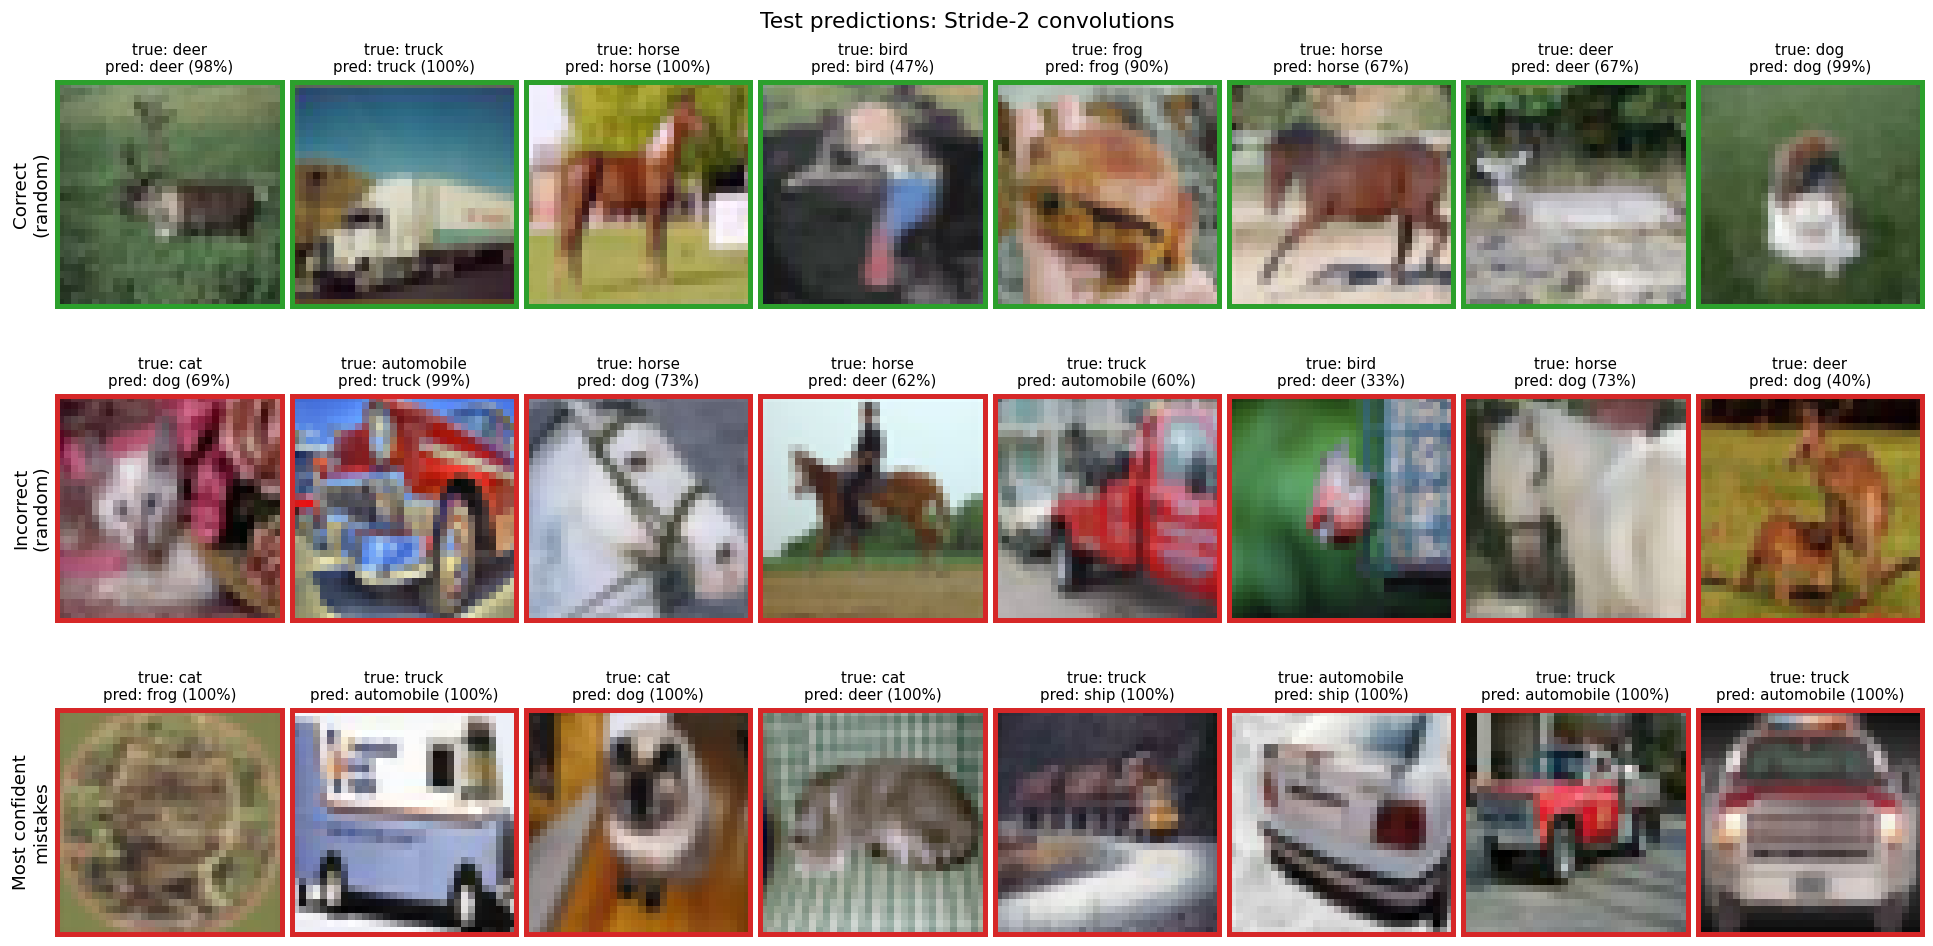

Mean confidence when correct:   86.0%
Mean confidence when incorrect: 61.3%
Mistakes made with at least 90% confidence: 225 of 2,147


In [ ]:
# Show correct and incorrect test predictions.
example_rng = np.random.default_rng(SEED)
correct_indices = np.flatnonzero(test_correct)
wrong_indices = np.flatnonzero(~test_correct)
n_show = 8
example_rows = {
    "Correct\n(random)": example_rng.choice(correct_indices, n_show, replace=False),
    "Incorrect\n(random)": example_rng.choice(wrong_indices, n_show, replace=False),
    "Most confident\nmistakes": wrong_indices[np.argsort(-test_confidence[wrong_indices])][:n_show],
}

fig, axes = plt.subplots(len(example_rows), n_show, figsize=(2 * n_show, 2.7 * len(example_rows)),
                         constrained_layout=True)
for r, (row_title, indices) in enumerate(example_rows.items()):
    for c, index in enumerate(indices):
        ax = axes[r, c]
        ax.imshow(test_dataset.data[index], interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(3)
            spine.set_color("tab:green" if test_correct[index] else "tab:red")
        ax.set_title(f"true: {class_names[test_labels_np[index]]}\n"
                     f"pred: {class_names[test_predictions[index]]} ({test_confidence[index]:.0%})",
                     fontsize=9)
    axes[r, 0].set_ylabel(row_title, fontsize=11)
fig.suptitle(f"Test predictions: {display_names[chosen_name]}", fontsize=13)
fig.savefig(ARTIFACT_DIR / "part4_examples.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Mean confidence when correct:   {test_confidence[test_correct].mean():.1%}")
print(f"Mean confidence when incorrect: {test_confidence[~test_correct].mean():.1%}")
print(f"Mistakes made with at least 90% confidence: "
      f"{(test_confidence[~test_correct] >= 0.9).sum()} of {len(wrong_indices):,}")

In [ ]:
# Summarize the test findings from the computed results and save them.
pair_counts = off_diagonal + off_diagonal.T
pairs = sorted(((pair_counts[i, j], i, j) for i in range(num_classes)
                for j in range(i + 1, num_classes)), reverse=True)[:3]
best = np.argsort(per_class_accuracy)[::-1][:3]
worst = np.argsort(per_class_accuracy)[:3]

display(Markdown(
    f"**Test summary.** The selected model ({display_names[chosen_name]}, epoch "
    f"{comparison[chosen_name]['selected_epoch']}) reaches **{test_accuracy:.2%}** test accuracy "
    f"(95% CI {test_low:.2%} to {test_high:.2%}). Its validation accuracy was "
    f"{chosen_val_accuracy:.2%}, a difference of {100 * (test_accuracy - chosen_val_accuracy):+.2f} "
    "percentage points. "
    "The easiest classes were " + ", ".join(f"{class_names[i]} ({per_class_accuracy[i]:.1%})" for i in best)
    + "; the hardest were " + ", ".join(f"{class_names[i]} ({per_class_accuracy[i]:.1%})" for i in worst)
    + ". The most frequently confused class pairs (both directions combined) were "
    + ", ".join(f"{class_names[i]}/{class_names[j]} ({n} images)" for n, i, j in pairs)
    + f". Mistakes had a mean confidence of {test_confidence[~test_correct].mean():.1%}, compared with "
    f"{test_confidence[test_correct].mean():.1%} for correct predictions."))

part4_results = {
    "selection_rule_checkpoint": "highest validation accuracy; earliest tie",
    "selection_rule_model": "highest selected-checkpoint validation accuracy; "
                            "ties -> fewer parameters, then shorter training time",
    "comparison": comparison,
    "chosen_model": chosen_name,
    "test_accuracy": test_accuracy,
    "test_accuracy_95ci": [test_low, test_high],
    "test_loss": test_loss,
    "per_class_accuracy": dict(zip(class_names, per_class_accuracy.tolist())),
    "per_class_precision": dict(zip(class_names, per_class_precision.tolist())),
    "confusion_matrix": confusion.tolist(),
    "hardware": hardware, "device": str(DEVICE),
    "torch_version": str(torch.__version__),
}
with (ARTIFACT_DIR / "part4_results.json").open("w") as file:
    json.dump(part4_results, file, indent=2)
print(f"Saved {ARTIFACT_DIR / 'part4_results.json'}")

**Test summary.** The selected model (Stride-2 convolutions, epoch 10) reaches **78.53%** test accuracy (95% CI 77.73% to 79.33%). Its validation accuracy was 77.72%, a difference of +0.81 percentage points. The easiest classes were automobile (91.0%), ship (90.3%), truck (87.9%); the hardest were cat (54.7%), bird (60.7%), dog (77.4%). The most frequently confused class pairs (both directions combined) were cat/dog (291 images), bird/deer (134 images), automobile/truck (127 images). Mistakes had a mean confidence of 61.3%, compared with 86.0% for correct predictions.

Saved artifacts/part4_results.json


### Discussion

**Model selection.** Using validation accuracy alone, we selected the stride-2 convolution model
at epoch 10, with 77.72% validation accuracy. The baseline reached 75.40% and the dropout model
72.22%. The lead over the baseline is 2.32 percentage points, or 116 of 5,000 validation images,
which is larger than the ±1.2-point sampling interval of either estimate. The paired comparison
gives the same answer. On identical validation images, only the strided model is right on 487
images and only the baseline on 371. A McNemar test on these 858 disagreements gives χ² ≈ 15.7,
p < 0.001. This shows the difference is unlikely to be validation-sampling noise. It does not
account for training randomness (see Limitations section below).

**Test results.** The selected checkpoint reaches **78.53%** test accuracy (95% CI 77.73% to
79.33%; test loss 0.6497). That is 0.81 points above its validation accuracy and within the
sampling uncertainty of both sets. Choosing the best of three models on the validation set did
not produce a visibly optimistic estimate here. The test set was used once, after the model was
fixed, so 78.53% is an unbiased estimate for this checkpoint.

Errors are concentrated in the animal classes. Cat (54.7%) and bird (60.7%) are by far the most difficult
classes, while automobile (91.0%), ship (90.3%), and truck (87.9%) are the easiest. The largest
confusions are between visually similar pairs: cat/dog (291 images in both directions, including
19.5% of all cats predicted as dog), bird/deer (134) and automobile/truck (127). Airplane and ship
are also confused (69 airplanes predicted as ship, 42 ships as airplane). These classes both have smooth
blue backgrounds, which suggests the model relies partly on background colour. *Deer* has the
lowest precision (69.8%) because birds, cats, frogs, horses and dogs on green or brown natural
backgrounds are often predicted as deer. It acts as a fallback class for animals in natural scenes.

**Correct and incorrect examples.** The random correct examples are mostly whole, centred objects
with a typical silhouette: a horse in side view, a truck trailer, a deer standing in grass.
Confidence still varies (for example, a correctly classified bird at 47%). The random mistakes are
mostly reasonable. They include close-ups of white horse heads predicted as dog, where the
legs and body that identify a horse are cut off, and a ridden horse predicted as deer. A red
vintage automobile is predicted as truck and a red pickup truck as automobile, and a bird is
predicted as deer, matching its green, foliage-like background. The most confident mistakes are
more concerning. Every one of them is at about 100% confidence. They include a curled-up, heavily textured
cat predicted as frog, a cat lying on a plaid blanket predicted as deer, trucks that look like vans,
pickups or SUVs predicted as automobile, and a white car and a dark truck predicted as ship. In these cases texture, colour or
background dominate the decision. On average the model is less confident when it is wrong (61.3%
against 86.0% when right), but 225 of its 2,147 mistakes are made with at least 90% confidence.
Its softmax probability is therefore a useful but poorly calibrated signal.

**Dropout trade-off.** Dropout adds no parameters and no measurable training time (170.5 s against
171.1 s for the baseline), and costs nothing at test time because `eval()` disables it. Within
10 epochs, however, it lowered validation accuracy by 3.18 points. Its checkpoint training accuracy
on clean images (73.37%) is only 1.15 points above its validation accuracy. The baseline's gap is
2.58 points (77.98% against 75.40%). Dropout narrowed the generalization gap, but by lowering
training performance, not by raising validation performance, so it underfits. The baseline was not
clearly overfitting, since augmentation already regularizes it. Dropout would be more likely to
help with longer training, a larger classifier head or a smaller dropout probability.

**Downsampling trade-off.** Replacing max pooling with learned stride-2 convolutions gave the best
validation accuracy (+2.32 points over the baseline) and the best clean training accuracy (80.94%).
Its generalization gap is slightly larger (3.22 points), consistent with its extra capacity. It
costs 193,760 extra parameters (+54%) and more computation per image. On the L4, however, total
fitting time rose by only 1.8% (174.2 s against 171.1 s). All three models took about 17 s per
epoch, which suggests the CPU data pipeline (augmentation with `num_workers=0`), not the GPU, limited
the speed. On slower hardware or with a faster input pipeline, the strided model's extra cost would
be more visible. Max pooling is parameter-free and has a built-in tolerance to small shifts. A
stride-2 convolution must learn how to summarize each region but can keep more information than a
single maximum. The comparison is confounded: the strided model also has more parameters and a
larger receptive field (29 × 29 against 22 × 22), so the gain cannot be attributed to learned
downsampling alone.

**Limitations and run-to-run variation.** Each model was trained once with seed 42. Results also
depend on random initialization, data order, augmentation and dropout masks, so another seed could
move accuracies by a fraction of a point or more. That is enough to change the result of a close
comparison. These numbers also differ slightly from an earlier run of the same notebook on a
Tesla T4 (for example, baseline validation accuracy 75.84% there against 75.40% here). This shows
that even a fixed seed does not reproduce results exactly across hardware. The confidence intervals and the
McNemar test only cover sampling uncertainty in the evaluation sets, not this training variation;
repeating each model over several seeds and reporting the mean and standard deviation would be
needed for that. The baseline and strided models peaked at the final epoch, so they were probably
still improving, and longer training could change the ranking. Only one learning rate, one dropout
probability and one strided design were tested. Timing comes from a single run on a shared cloud
GPU, so differences of a few seconds are not meaningful.